In [10]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import joblib
import os
from huggingface_hub import hf_hub_download
import shutil
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

In [11]:
data_path = 'dataset_model/dataset_trainable_rev2.csv'

In [12]:
if os.path.exists(data_path):
    print(f"Dataset Raw lokal sudah ada di '{data_path}'.")
else:
    print(f"Dataset Raw lokal belum ada. Mengunduh dataset dari Hugging Face...")
    
    temp_downloaded_path = hf_hub_download(
        repo_id="vel740/dhaka-smart-waste-processed",
        filename="processed/dataset_trainable_rev2.csv",
        repo_type="dataset"
    )
    
    os.makedirs('dataset_model', exist_ok=True)
    shutil.copy(temp_downloaded_path, data_path)
    print(f"Dataset selesai diunduh dan tersimpan di '{data_path}'.")

df = pd.read_csv(data_path)
print(f"Total baris awal: {len(df):,} baris")

Dataset Raw lokal sudah ada di 'dataset_model/dataset_trainable_rev2.csv'.
Total baris awal: 15,650 baris


In [13]:
# Hitung selisih target dan lag ke-3 untuk mendeteksi event pickup (> 20% drop)
target_diff = df['target_next_hour'] - df['fill_level_percent']
velocity_3h = df['lag_2h'] - df['lag_3h']

# Hanya ambil fase akumulasi murni (bebas dari drop pengangkutan sampah)
clean_mask = (
    (target_diff > -20.0) & 
    (df['velocity_1h'] > -20.0) & 
    (df['velocity_2h'] > -20.0) & 
    (velocity_3h > -20.0)
)

df_clean = df[clean_mask].reset_index(drop=True)
print(f"Total baris setelah pembersihan event pickup: {len(df_clean):,} baris (Dibuang: {len(df) - len(df_clean)} baris)")

Total baris setelah pembersihan event pickup: 15,650 baris (Dibuang: 0 baris)


In [14]:
features = ['fill_level_percent', 'lag_1h', 'lag_2h', 'lag_3h', 'lag_24h', 'lag_48h', 
            'is_weekend', 'velocity_1h', 'velocity_2h', 'hour_sin', 'hour_cos', 'day_sin', 'day_cos']
target = 'target_next_hour'

split_timestamp = df_clean['timestamp_unix'].quantile(0.8)
train_mask = df_clean['timestamp_unix'] <= split_timestamp
test_mask = df_clean['timestamp_unix'] > split_timestamp

X_train_raw = df_clean.loc[train_mask, features].values
X_test_raw = df_clean.loc[test_mask, features].values
y_test_raw = df_clean.loc[test_mask, target].values

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_raw)
X_test_scaled = scaler.transform(X_test_raw)

In [15]:
lgbm_model = joblib.load('model/lightgbm_smartbin_16days_final.pkl')
lgbm_preds = lgbm_model.predict(X_test_raw)

c:\Users\ardel\.conda\envs\pytorch_gpu_env\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


In [16]:
class SmartBinLSTM(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers, output_size, dropout_rate):
        super(SmartBinLSTM, self).__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        lstm_drop = dropout_rate if num_layers > 1 else 0.0
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True, dropout=lstm_drop)
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(x.device)
        c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(x.device)
        out, _ = self.lstm(x, (h0, c0))
        return self.fc(out[:, -1, :]).squeeze()

def create_sequences(X, seq_length):
    return np.array([X[i:(i + seq_length)] for i in range(len(X) - seq_length)])

In [17]:
SEQ_LENGTH = 6
X_test_seq = create_sequences(X_test_scaled, SEQ_LENGTH)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
lstm_model = SmartBinLSTM(len(features), 64, 1, 1, 0.4077).to(device)
lstm_model.load_state_dict(torch.load('model/lstm_smartbin_16days_final.pth', weights_only=True))
lstm_model.eval()

with torch.no_grad():
    X_tensor = torch.tensor(X_test_seq, dtype=torch.float32).to(device)
    lstm_preds = lstm_model(X_tensor).cpu().numpy()

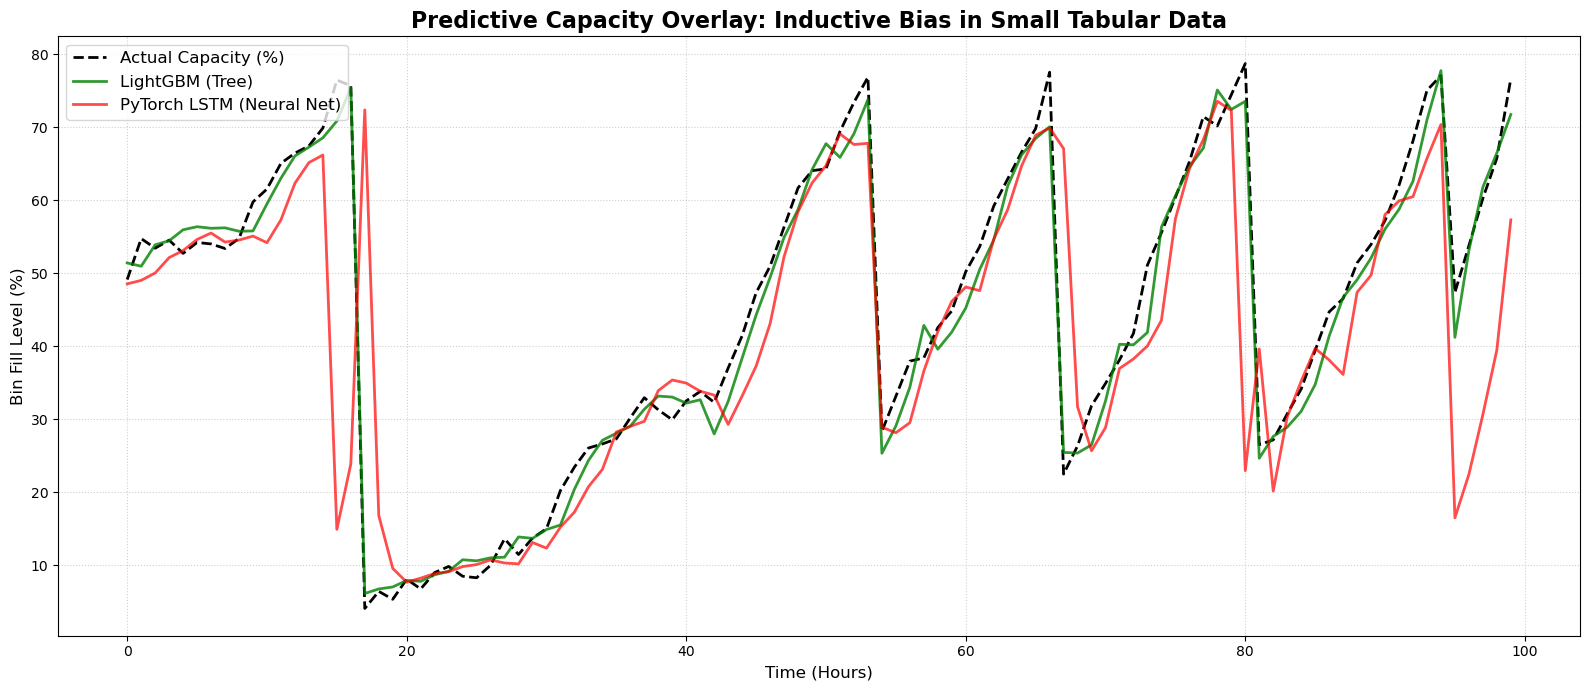

In [18]:
actuals_aligned = y_test_raw[SEQ_LENGTH:]
lgbm_aligned = lgbm_preds[SEQ_LENGTH:]

# We will plot a zoomed-in 100-hour window so the anomalies are visible
WINDOW_START = 200
WINDOW_END = 300

plt.figure(figsize=(16, 7))
plt.plot(actuals_aligned[WINDOW_START:WINDOW_END], label='Actual Capacity (%)', color='black', linewidth=2, linestyle='--')
plt.plot(lgbm_aligned[WINDOW_START:WINDOW_END], label='LightGBM (Tree)', color='green', linewidth=2, alpha=0.8)
plt.plot(lstm_preds[WINDOW_START:WINDOW_END], label='PyTorch LSTM (Neural Net)', color='red', linewidth=2, alpha=0.7)

plt.title('Predictive Capacity Overlay: Inductive Bias in Small Tabular Data', fontsize=16, fontweight='bold')
plt.xlabel('Time (Hours)', fontsize=12)
plt.ylabel('Bin Fill Level (%)', fontsize=12)
plt.legend(loc='upper left', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()